## 오늘 할 일

- **Practice 1**: 엘니뇨가 강한 해에 전주의 12월 강수는 많았을까, 적었을까?
- **Practice 2**: 전주에 비가 많이 온 해, 태평양 바다 온도는 어떤 모양이었을까?

**회귀선과 잔차**

$$
y_i^* = a x_i + b, \qquad \varepsilon_i = y_i - y_i^*
$$

- $a$ : 회귀계수 (`slope`) — $x$ 가 1 증가할 때 $y$ 의 평균적인 변화량 (단위: $y$ 단위 / $x$ 단위)
- $b$ : 절편 (`intercept`) — $x = 0$ 일 때 $y^*$ 의 값

## Practice 1 regression analysis between winter (DEC) Precip_jeonju and winter ENSO index

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature 

from scipy import stats

In [2]:

################ Jeonju Precipitation index ################
#------------ Read .csv data -------------
data = pd.read_csv('../data/rn_20260928132312.csv', encoding='euc-kr', skiprows=7)
data.head()

,년월,지점,강수량(mm)
0,1980-01,146,37.1
1,1980-02,146,16.1
2,1980-03,146,63.4
3,1980-04,146,138.3
4,1980-05,146,116.7


In [3]:

#--------- Make a new Pandas Dataframe ----------
dates = pd.DatetimeIndex(data['년월'])  # set 'time' as date
precip = data['강수량(mm)']             # select precip data

In [4]:
pdata1 = pd.DataFrame({'time': dates, '강수량(mm)': precip}) 
pdata2 = pdata1.set_index(['time'])    # Set 'time' as index

In [5]:
#------ Convert Pandas Dataframe to xarray -----
# [0, :]: variable 방향 0번째(강수량), time은 전부 → 1차원 시계열
pr = pdata2.to_xarray().to_array()[0, :]
print(pr.shape)                               # (N,)

(552,)


In [6]:
#------ Calculate climatology -----
pr_clim = pr.sel(time=slice('1980-01','2022-12')).groupby('time.month').mean(dim='time')   

#---------- Calculate anomalies ------------
pranom = pr.groupby('time.month') - pr_clim

#------ Select December data -----
pr_dec = pranom[23::12]     # from 1981-12, Dec data only 
pr_dec = pr_dec.sel(time=slice('1982-12','2022-12'))  # from 1982-12 to 2022-12

In [7]:
######################## ENSO index ########################
#------------ Reading .nc data -------------
dset = xr.open_dataset('../data/sst.mnmean.nc')   
sst=dset.sst.sel()

In [8]:

#------------ Calculate Nino index ---------
nino34 = sst.where((sst.lat<5) & (sst.lat>-5) & (sst.lon>190) & (sst.lon<240), drop=True).mean(dim=['lat','lon'])

#---------- Calculate climatology ----------
clim = nino34.sel(time=slice('1982-01', '2022-12')).groupby('time.month').mean(dim='time')   

#---------- Calculate anomalies ------------
anom = (nino34.groupby('time.month') - clim)

#---------Take 3-month running mean---------
nino3mon = anom.rolling(time=3, center=True).mean()

In [9]:

#--------Pick up a specific season ---------
ninos = nino3mon[12::12]  # NDJ from 1982
ninos = ninos.sel(time=slice('1982-12','2022-12'))  # from 1982-12 to 2022-12]

https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html 
 
## `scipy.stats.linregress`

두 변수의 단순 선형회귀를 최소제곱법으로 계산한다.

```python
slope, intercept, rvalue, pvalue, stderr = stats.linregress(x, y)
```

### 입력

**x** : 1차원 배열 — 독립변수 (Practice 1: `ninos`)

**y** : 1차원 배열 — 종속변수 (Practice 1: `pr_dec`), `x` 와 길이가 같아야 함

### 출력

| 이름 | 뜻 |
|---|---|
| `slope` | 회귀계수 $a$ (기울기) |
| `intercept` | 절편 $b$ |
| `rvalue` | 상관계수 $r$ |
| `pvalue` | "기울기가 0이다"라는 가설의 p-value |
| `stderr` | 기울기의 표준오차 |

결과로 회귀선 $y^* = a x + b$ 를 얻는다.

> `rvalue`, `pvalue`, `stderr` 는 다음 시간(상관분석)에 자세히 다룬다.


In [10]:
##################  Regression ##################### 
slope,intercept,rvalue,pvalue,stderr= stats.linregress(ninos,pr_dec)
print(slope,intercept,rvalue,pvalue,stderr)


7.28167261224482 -0.1770785576209119 0.5124573321659517 0.0006138313216552504 1.9538400817972799


In [11]:
prprd = slope*ninos+intercept  # For fitted line

$$
y^* = a\,x + b \qquad \longleftrightarrow \qquad \texttt{prprd = slope * ninos + intercept}
$$

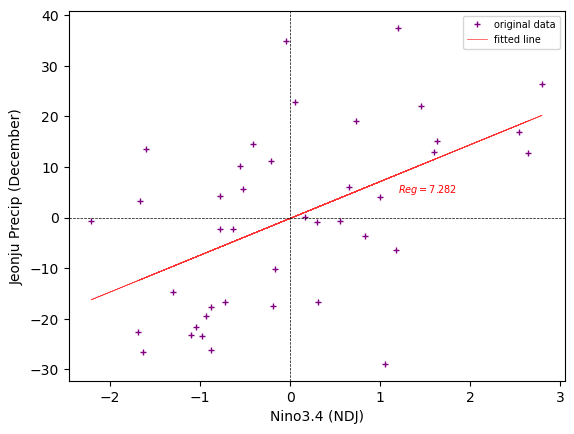

In [12]:
##################  Plotting ##################### 
fig, ax = plt.subplots()

ax.plot(ninos, pr_dec, '+', c='purple', markersize=4, label='original data')   
# same as   ax2.scatter(ninos, pr, s=15, c='purple', marker='+', ... )
ax.plot(ninos, prprd, c='r', lw=0.5, alpha=0.8, label='fitted line')
ax.axhline(0,color='k', linewidth=0.5, linestyle='dashed')
ax.axvline(0,color='k', linewidth=0.5, linestyle='dashed')
ax.set_xlabel('Nino3.4 (NDJ)')
ax.set_ylabel('Jeonju Precip (December)')
ax.legend(fontsize=7)
txt=r'$Reg={:.3f}$'.format(slope)
ax.text(1.2, 5.0, txt, c='r', size=7) 

plt.show()


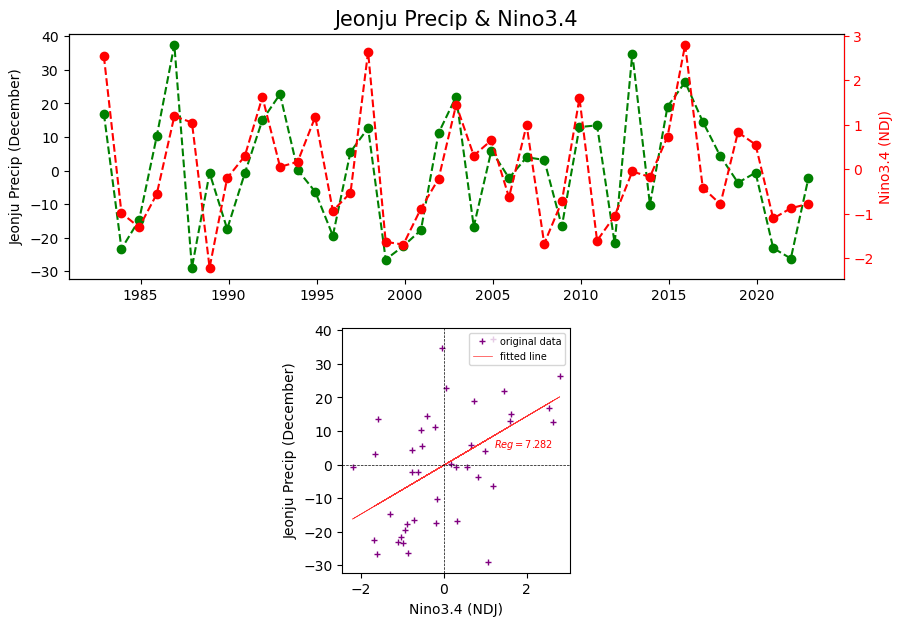

In [13]:
##################  Plotting ##################### 
fig = plt.figure(figsize=(10,7), dpi=100)

# -------------- Figure 1 ----------------
ax1 = plt.subplot(211)
ax1b = ax1.twinx()       # plot on the right axis
       
#--- Precip Graph
ax1.plot(pr_dec.time.values, pr_dec, color = 'g', marker='o', linestyle='dashed', linewidth=1.5, label = "Jangma Days")
ax1.set_ylabel('Jeonju Precip (December)')
# ax1.legend(loc='upper left')
ax1.set_title('Jeonju Precip & Nino3.4', fontsize=15)

#--- Nino3.4 Graph 2
ax1b.plot(ninos.time.values, ninos, color = 'r', marker='o', linestyle='dashed', linewidth=1.5, label = "Precip Days")
ax1b.set_ylabel('Nino3.4 (NDJ)', color='r')
# ax1b.legend(loc='upper left')
ax1b.spines['right'].set_color('r')
ax1b.spines['right'].set_position(('axes',1.0))
ax1b.tick_params(axis='y',color = 'r', labelcolor = 'r')

# ---------------- Figure 2 ---------------
ax2 = plt.subplot(235)
ax2.plot(ninos, pr_dec, '+', c='purple', markersize=4, label='original data')  # = ax2.scatter(ninos, pr, s=15, c='purple', marker='+', )
ax2.plot(ninos, prprd, c='r', lw=0.5, alpha=0.8, label='fitted line')
ax2.axhline(0,color='k',linewidth=0.5,linestyle='dashed')
ax2.axvline(0,color='k',linewidth=0.5,linestyle='dashed')
ax2.set_xlabel('Nino3.4 (NDJ)')
ax2.set_ylabel('Jeonju Precip (December)')
ax2.legend(fontsize=7)
txt=r'$Reg={:.3f}$'.format(slope)
ax2.text(1.2, 5.0, txt, c='r', size=7) 

plt.show()


## Practice 2 Regressed SST pattern onto Precip_Jeonju

In [14]:
#---------- Calculate climatology ----------
clim = sst.sel(time=slice('1982-01', '2022-12')).groupby('time.month').mean(dim='time')  
#---- Calculate anomalies and select DEC data ---
anomt = (sst.groupby('time.month') - clim)
anom = anomt.rolling(time=3, center=True).mean(dim='time')[12::12]    # Select from 1982
anom = anom.sel(time=slice('1982-12','2022-12'))  # from 1982-12 to 2022-12

/tmp/ipykernel_1377530/3640137812.py:5: FutureWarning: Reductions are applied along the rolling dimension(s) '['time']'. Passing the 'dim' kwarg to reduction operations has no effect.
  anom = anomt.rolling(time=3, center=True).mean(dim='time')[12::12]    # Select from 1982


In [15]:
reg, interc, corr, pval= np.apply_along_axis(lambda y,x: stats.linregress(x,y)[0:4],axis=0,arr=anom,x=pr_dec)

### 격자마다 회귀하기

```python
reg, interc, corr, pval = np.apply_along_axis(
    lambda y, x: stats.linregress(x, y)[0:4], axis=0, arr=anom, x=pr_dec)
```

- **`np.apply_along_axis(함수, axis=0, arr=anom, x=pr_dec)`** : `axis=0`(시간)을 따라 격자 한 점의 자료를 꺼내고, 꺼낸 자료마다 함수를 적용한다. 이것을 모든 격자에 반복한다.
  - `x=pr_dec` : 전주 강수 시계열
- **`[0:4]`** : `linregress` 결과 중 앞의 4개(`slope`, `intercept`, `rvalue`, `pvalue`)만 받는다. 그래서 `reg`, `interc`, `corr`, `pval` 4개의 지도가 나온다.


**`lambda` 란?** 아래 두 코드는 같은 일을 한다.


```python
def reg_one_point(y, x):
    return stats.linregress(x, y)[0:4]

np.apply_along_axis(reg_one_point, axis=0, arr=anom, x=pr_dec)
```



```python
np.apply_along_axis(lambda y, x: stats.linregress(x, y)[0:4], axis=0, arr=anom, x=pr_dec)
```

한 번만 쓸 함수라면 `def` 로 이름을 짓지 않고, 쓸 자리에 바로 적을 수 있다. 이것이 `lambda` 다.

<>:13: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1377530/2977674722.py:13: SyntaxWarning: invalid escape sequence '\d'
  plt.colorbar(orientation = "horizontal", pad=0.06, aspect= 30, label='[$\degree$C / mm day$^{-1}$]')


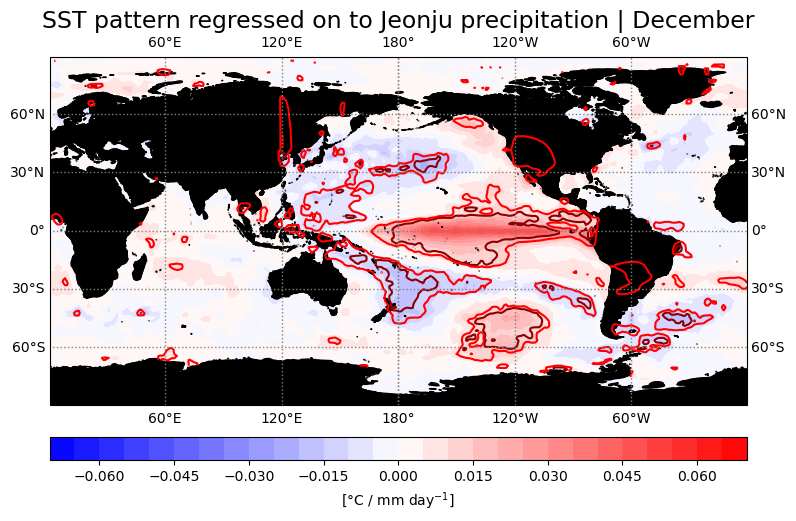

In [16]:
##########################  Plotting  ############################
# ----------- Set Figure  ------------
fig = plt.figure(figsize=(9,7))   # Figure 
ax = plt.axes(projection = ccrs.PlateCarree(180))   # Axes 

# ----------- Plot figure ------------
lons = anom["lon"]
lats = anom["lat"]

clevs=np.around(np.arange(-0.07, 0.07, 0.005), 3)

plt.contourf(lons, lats, reg, levels = clevs, cmap='bwr', transform=ccrs.PlateCarree())
plt.colorbar(orientation = "horizontal", pad=0.06, aspect= 30, label='[$\degree$C / mm day$^{-1}$]')
plt.contour(lons, lats, pval, levels=[0.01, 0.05], colors=['darkred', 'red'], transform=ccrs.PlateCarree())

# ----------- Set Axes properties  ------------
ax.set_title('SST pattern regressed on to Jeonju precipitation | December', fontsize=17)
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, linestyle=':', color='gray')
ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '50m', edgecolor='face', facecolor='black'))

# ----------- Save plot  ------------
plt.savefig('jeonju_precip_regression_sst_dec.png')
plt.show()
